# 07 · USuRPER: periodicity in the spectra themselves

**What you'll learn**

- the USuRPER idea: each spectrum is a point on a unit hypersphere, and a period shows up as
  spectra close in *phase* being close on the sphere
- that it needs no template and no RVs, and finds the RV period when the star simply moves
- that it also finds changes that are *not* Doppler shifts: a temperature change, and an
  unresolved twin binary (at half the orbital period)
- when to reach for it, and its limits

Every step is a public function on plain arrays (`sparta.pdc`, `unicor`, the simulator,
`phoenix_spectrum`). The last cell repeats the analysis with the objects and checks that the
numbers agree.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.timeseries import LombScargle

from sparta.instruments.simulated import Simulation, component_spectra, simulate, upper_envelope
from sparta.pdc import (pdc_power, pdc_pvalue, phase_distance_matrix, resample_spec_to_common_grid,
                        spectral_distance_matrix, unbiased_u_centering)
from sparta.plotting import EXTRA_COLOR, GREY, apply_style, plot_curve, plot_data, plot_points
from sparta.preprocess import resample_to_log_grid
from sparta.template import phoenix_spectrum
from unicor import ccf_order, dsp

# Apply the SPARTA figure style
apply_style()

# Period (d) and power of the highest periodogram peak
def peak(freqs, power):
    """(period in days, power) of the highest peak of a periodogram on freqs (1/day)."""
    k = np.argmax(power)
    return 1 / freqs[k], power[k]

# Periodogram power at the grid frequency nearest a given period
def power_at(freqs, power, period):
    """Power at the grid frequency closest to 1/period (period in days)."""
    return power[np.argmin(np.abs(freqs - 1 / period))]

# UNICOR RV per epoch: log-λ resampling, then CCF against one template
def measure_rvs(waves, fluxes, t_wave, t_flux, dv=0.1, vel_bound=30):
    """UNICOR RV, its uncertainty (km/s) and the CCF peak of each single-order spectrum
    against one rest-frame template (notebook 03): log-λ resampling, then ccf_order."""
    n_lags = int(round(vel_bound / dv))
    orders = []
    for w, f in zip(waves, fluxes):
        log_w, log_f = resample_to_log_grid(w, f, dv)
        orders.append(ccf_order(log_w, log_f, t_wave, t_flux, n_lags, dv_kms=dv,
                                native_step_kms=dsp.dv_from_wave(w), errors=True))
    return (np.array([o.rv for o in orders]), np.array([o.erv for o in orders]),
            np.array([o.peak for o in orders]))

## 1. The idea

Take one spectral order of each epoch, resampled to a common wavelength grid. Subtract its mean
and divide by its norm: spectrum $i$ becomes a unit vector $\mathbf{x}_i$, a point on a
hypersphere with one dimension per pixel. Two spectra are as far apart as the chord between
their points,

$$d_{ij} = \lVert \mathbf{x}_i - \mathbf{x}_j \rVert = \sqrt{2\,(1 - \mathbf{x}_i\cdot\mathbf{x}_j)},$$

0 for identical spectra, larger the more they differ, whatever the difference is (a shift, deeper
lines, a blend). USuRPER (Binnenfeld, Shahaf & Zucker 2020, A&A 642, A146) feeds these distances
to the phase distance correlation (PDC) of Zucker (2018; notebook 06): at each trial frequency it
asks whether spectra close in *phase* are also close on the sphere.

No template and no RVs enter, so anything that changes the spectrum periodically is found,
Doppler shift or not. The recipe step by step: [periodograms § USuRPER](../../docs/periodograms.md#usurper-binnenfeld-shahaf--zucker-2020).

The three examples share one observing schedule: 36 epochs at random times over 80 days. Trial
frequencies run from 0.02 to 1 per day, in steps of 0.0005/day (several points per peak, which
is about $1/T$ = 0.0125/day wide).

In [2]:
# Observing schedule: 36 random epochs over 80 days (d)
rng = np.random.default_rng(3)
t = np.sort(rng.uniform(0, 80, 36))                     # days
n = t.size
# Trial frequency grid (1/day) and the one 60 Å order used throughout
freqs = np.arange(0.02, 1.0, 1 / 2000)                  # 1/day
WINDOW = (5000.0, 5060.0)                               # one 60 Å order (air)
print(f"{n} epochs over {np.ptp(t):.1f} days")

36 epochs over 77.8 days


## 2. Example A: a star that moves

A sanity check: a Sun-like star (PHOENIX 5500 K) on a circular orbit, $P$ = 4.3 days and
$K$ = 3 km/s, simulated like HARPS in one 60 Å order at signal-to-noise 100 per pixel
(`simulate` returns one record of plain arrays per epoch). RVs and USuRPER should find the same
period.

In [3]:
# Example A: injected circular orbit, a pure Doppler signal
P_A, K_A = 4.3, 3.0                                     # days, km/s
rv_A = K_A * np.sin(2 * np.pi * t / P_A)
# Simulate HARPS-like spectra of the moving star (S/N 100 per pixel)
sim_A = Simulation(like="HARPS", windows_A=[WINDOW], components=[dict(teff=5500, logg=4.5, vsini=2.0)],
                   times=t, rv_kms=rv_A, snr=100, noise="constant", seed=11)
records_A, _ = simulate(sim_A)
# Keep the single order of each epoch as plain wavelength and flux arrays
waves = [rec.wave[0] for rec in records_A]              # Å (air)
fluxes = [rec.flux[0] for rec in records_A]
print(f"{len(waves)} spectra of {waves[0].size} pixels, {waves[0][0]:.1f}-{waves[0][-1]:.1f} Å")

36 spectra of 5869 pixels, 5000.0-5060.0 Å


**The sphere.** `resample_spec_to_common_grid` puts every spectrum on the wavelength range common
to all (at the finest median pixel step), subtracts its mean and divides by its norm: one unit
vector per epoch, the columns of a matrix. `spectral_distance_matrix` takes the chords between
them, the distances that USuRPER uses.

In [4]:
# Each spectrum becomes a unit vector: mean subtracted, norm 1, columns = epochs
X = resample_spec_to_common_grid(waves, fluxes, factor=1)    # (pixels, epochs)
norms = np.sqrt(np.sum(X ** 2, axis=0))
print(f"{X.shape[1]} points on a sphere in {X.shape[0]} dimensions: column means within "
      f"{np.abs(X.mean(axis=0)).max():.0e} of 0, norms {norms.min():.12f} to {norms.max():.12f}")

# Chord distances between all pairs of spectra, checked against the by-hand formula
d = spectral_distance_matrix(waves, fluxes)
chord = np.sqrt(2 * (1 - np.sum(X[:, 0] * X[:, 1])))
print(f"chord between epochs 0 and 1: {chord:.6f}; spectral_distance_matrix: {d[0, 1]:.6f}")
assert np.isclose(chord, d[0, 1], rtol=1e-12)

36 points on a sphere in 5869 dimensions: column means within 1e-17 of 0, norms 1.000000000000 to 1.000000000000
chord between epochs 0 and 1: 0.388012; spectral_distance_matrix: 0.388012


Because each spectrum is mean-subtracted and normalised first, a change of flux scale or offset
(a cloud, a different exposure time) moves nothing on the sphere:

In [5]:
# Rescale and offset one spectrum: its point on the sphere must not move
rescaled = [1.7 * f + 0.3 if i == 0 else f for i, f in enumerate(fluxes)]
# Largest change in any distance
moved = np.abs(spectral_distance_matrix(waves, rescaled) - d).max()
print(f"distances between spectra: {d[np.triu_indices_from(d, 1)].min():.3f} to {d.max():.3f}")
print(f"largest change after rescaling spectrum 0 by 1.7 and adding 0.3: {moved:.1e}")
assert moved < 1e-12

distances between spectra: 0.055 to 1.003
largest change after rescaling spectrum 0 by 1.7 and adding 0.3: 1.9e-15


At the true period, pairs of spectra close in phase should be close on the sphere, and pairs half a
cycle apart (opposite velocities) far apart. At a wrong period the phases are scrambled. The plot
uses the phase separation $\Delta\varphi$ folded into [0, 0.5]; the PDC's phase distance,
$\Delta\varphi(1-\Delta\varphi)$ in units of $P^2$ (`phase_distance_matrix`), increases with it.

P = 4.3 d: Pearson correlation of chord distance and phase distance = +0.65
P = 3.1 d: Pearson correlation of chord distance and phase distance = -0.06


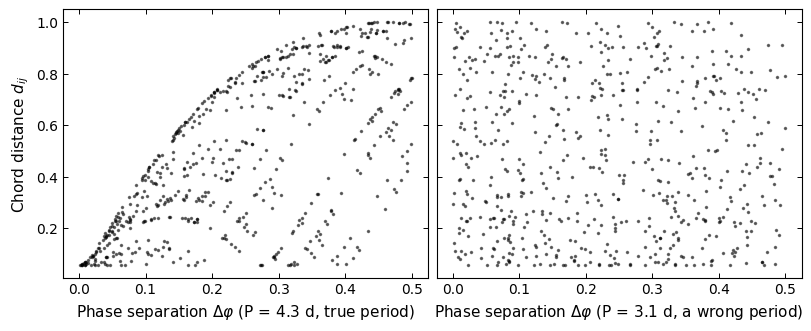

In [6]:
# Plot the chord distance against phase separation, at the true and a wrong period
iu = np.triu_indices(n, 1)
fig, axs = plt.subplots(1, 2, figsize=(8, 3.2), sharey=True)
for ax, period, label in zip(axs, (P_A, 3.1), ("true period", "a wrong period")):
    dphi = ((t[:, None] - t[None, :]) / period) % 1.0
    dphi = np.minimum(dphi, 1 - dphi)
    plot_points(ax, dphi[iu], d[iu], ms=1.5, alpha=0.5)
    ax.set_xlabel(rf"Phase separation $\Delta\varphi$ (P = {period} d, {label})")
    b = phase_distance_matrix(t, 1 / period)[iu]
    print(f"P = {period} d: Pearson correlation of chord distance and phase distance "
          f"= {np.corrcoef(b, d[iu])[0, 1]:+.2f}")
axs[0].set_ylabel(r"Chord distance $d_{ij}$")
plt.show()

The periodogram turns this into a number per trial frequency: `pdc_power` of the U-centred
chord distances (notebook 06), a distance correlation, which also catches non-linear dependence.
`pdc_pvalue` gives the *local* p-value of a peak, at one frequency, not a false-alarm
probability over the grid ([periodograms § p-values](../../docs/periodograms.md#p-values)). GLS on the measured RVs
(UNICOR against the star's rest-frame model, `component_spectra`) is the reference:

In [7]:
# Reference: UNICOR RVs against the star's rest-frame model (km/s)
vels_A, evels_A, _ = measure_rvs(waves, fluxes, *component_spectra(sim_A)[0][0])
print(f"RV rms about the truth: {np.std(vels_A - rv_A) * 1e3:.1f} m/s "
      f"(median uncertainty {np.median(evels_A) * 1e3:.1f} m/s)")

# Periodograms: GLS of the RVs, USuRPER (PDC of the chord distances) of the spectra
gls_A = LombScargle(t, vels_A).power(freqs)                       # the RVs
usurper_A = pdc_power(t, freqs, unbiased_u_centering(d, n))       # the spectra
# Report each periodogram's highest peak
for name, power in (("GLS", gls_A), ("USuRPER", usurper_A)):
    print(f"{name:8s}: highest peak at P = {peak(freqs, power)[0]:.3f} d (power {peak(freqs, power)[1]:.2f})")
print(f"local p-value of the USuRPER peak: {pdc_pvalue(usurper_A.max(), n):.0e}")

RV rms about the truth: 2.3 m/s (median uncertainty 2.6 m/s)
GLS     : highest peak at P = 4.301 d (power 1.00)
USuRPER : highest peak at P = 4.310 d (power 0.66)
local p-value of the USuRPER peak: 6e-07


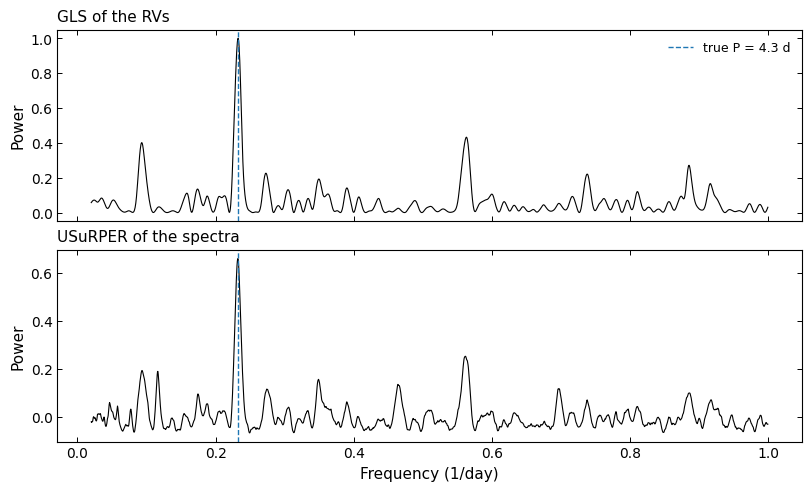

In [8]:
# Stack periodogram panels with the true periods marked
def show_periodograms(freqs, panels, truths):
    """One panel per periodogram (panels: title -> power); truths: (period in days, label, linestyle)."""
    fig, axs = plt.subplots(len(panels), 1, figsize=(8, 2.4 * len(panels)), sharex=True)
    for ax, (title, power) in zip(axs, panels.items()):
        plot_curve(ax, freqs, power, lw=0.8)
        for period, truth_label, ls in truths:
            ax.axvline(1 / period, color=EXTRA_COLOR, ls=ls, lw=1, label=truth_label)
        ax.set_ylabel("Power")
        ax.set_title(title, loc="left")
    axs[0].legend(loc="upper right")
    axs[-1].set_xlabel("Frequency (1/day)")
    return fig, axs

show_periodograms(freqs, {"GLS of the RVs": gls_A, "USuRPER of the spectra": usurper_A},
                  [(P_A, f"true P = {P_A} d", "--")])
plt.show()

Same period, from the RVs and from the spectra alone. For a star that only moves, the RVs stay
the tool of choice: they feed an orbit fit (notebook 09). USuRPER earns its keep when the change
is not a shift.

## 3. Example B: a temperature change, no motion at all

A toy pulsating star: its spectrum is a periodic mix of two PHOENIX models with $\log g$ = 4.5
and [M/H] = 0,

$$F(t) = \bigl(1 - w(t)\bigr)\,F_{4900} + w(t)\,F_{5500}, \qquad w(t) = 0.5 + 0.4\sin(2\pi t/P),$$

with $P$ = 5.7 days. The mix stands in for a temperature swinging between roughly 4950 and
5450 K. It is not a real atmosphere at the intermediate temperatures, but it changes the line
depths and blends the way a temperature change does. Nothing is shifted.

We build the spectra as the simulator does: `phoenix_spectrum` (bundled cache only), a fine
log-λ grid (notebook 02), a continuum by `upper_envelope`, rotational and instrumental
(FWHM $c/R$) broadening, then sampling at the observed pixels.

In [9]:
# HARPS-like pixel grid (observed) and a finer grid for building the models
R_HARPS = 120_000
native = dsp.C_KMS / (R_HARPS * 4.1)                    # km/s, HARPS's native pixel
pixels, _ = dsp.log_lambda_grid(*WINDOW, native)        # the observed pixels (Å, air)
lo, hi = WINDOW[0] - 15, WINDOW[1] + 15
fine, _ = dsp.log_lambda_grid(lo, hi, native / 8)       # 8 times finer, with a margin
dv_fine = dsp.dv_from_wave(fine)                        # its velocity step (km/s)

# Build a continuum-normalised, rotation- and instrument-broadened PHOENIX model
def rest_spectrum(teff, logg=4.5, vsini=2.0):
    """A continuum-normalised, broadened PHOENIX model (air) on the fine grid."""
    wave, flux = phoenix_spectrum(teff, logg, wave_range=(lo - 5, hi + 5), air=True,
                                  allow_download=False)
    f = dsp.resample(wave, flux, fine, kind="cubic")
    f = f / upper_envelope(fine, f)                     # continuum 1, same recipe for both
    f = dsp.broaden_rotational(f, dv_fine, vsini, 0.6)
    return dsp.broaden_gaussian(f, dv_fine, dsp.C_KMS / R_HARPS)

# The two models, then sampled at the observed pixels
cool, hot = rest_spectrum(4900), rest_spectrum(5500)
f_cool = dsp.resample(fine, cool, pixels, kind="cubic")
f_hot = dsp.resample(fine, hot, pixels, kind="cubic")
print(f"rms difference between the 4900 K and 5500 K spectra: {np.std(f_hot - f_cool):.3f} "
      f"(noise per pixel at S/N 100: 0.010)")

rms difference between the 4900 K and 5500 K spectra: 0.088 (noise per pixel at S/N 100: 0.010)


In [10]:
# Example B: a periodic mix of the cool and hot models, no motion, plus noise (S/N 100)
P_B, A_B = 5.7, 0.4
w = 0.5 + A_B * np.sin(2 * np.pi * t / P_B)
noise = np.random.default_rng(12).standard_normal((n, pixels.size)) / 100
fluxes_B = [(1 - wk) * f_cool + wk * f_hot + nk for wk, nk in zip(w, noise)]
waves_B = [pixels] * n
print(f"{len(fluxes_B)} spectra; w(t) from {w.min():.2f} to {w.max():.2f}")

36 spectra; w(t) from 0.10 to 0.90


What changes between the hottest and the coolest epoch: line depths, not line positions. The
cooler spectrum has deeper lines and more of them, so the difference (bottom) is positive almost
everywhere; a Doppler shift would instead leave a +/- pair at every line (the line's derivative).

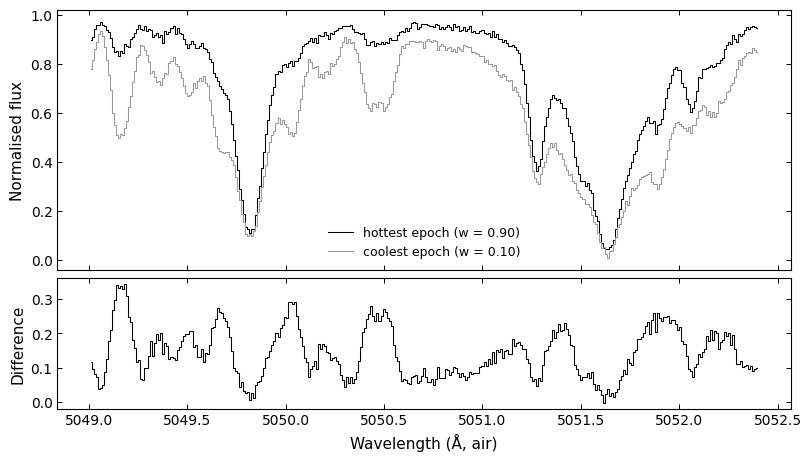

In [11]:
# Compare the hottest and coolest epochs: line depths change, positions do not
i_hot, i_cool = np.argmax(w), np.argmin(w)
zoom = (pixels > 5049.0) & (pixels < 5052.4)
fig, axs = plt.subplots(2, 1, figsize=(8, 4.5), sharex=True, height_ratios=[2, 1])
plot_data(axs[0], pixels[zoom], fluxes_B[i_hot][zoom], label=f"hottest epoch (w = {w[i_hot]:.2f})")
plot_data(axs[0], pixels[zoom], fluxes_B[i_cool][zoom], color=GREY,
          label=f"coolest epoch (w = {w[i_cool]:.2f})")
plot_data(axs[1], pixels[zoom], (fluxes_B[i_hot] - fluxes_B[i_cool])[zoom])
axs[0].set_ylabel("Normalised flux")
axs[1].set_ylabel("Difference")
axs[1].set_xlabel("Wavelength (Å, air)")
axs[0].legend(loc="lower center")
plt.show()

**The RVs.** UNICOR against the mean spectrum ($w$ = 0.5), the best single template one could
pick:

In [12]:
# Single template for the RVs: the mean spectrum
mean_flux = 0.5 * (cool + hot)                          # the w = 0.5 template, on the fine grid
# UNICOR RVs of every epoch against that template (km/s)
vels_B, evels_B, peaks_B = measure_rvs(waves_B, fluxes_B, fine, mean_flux)
# Fit a sinusoid in phase with w(t) to the RVs: the spurious-RV amplitude
semi, offset = np.polyfit(np.sin(2 * np.pi * t / P_B), vels_B, 1)   # RV = semi sin + offset
residual = vels_B - (semi * np.sin(2 * np.pi * t / P_B) + offset)
print(f"RV amplitude in phase with w(t): {semi * 1e3:+.1f} m/s; correlation of the RVs with w(t): "
      f"{np.corrcoef(vels_B, w)[0, 1]:.2f}")
print(f"RV scatter about that sinusoid: {np.std(residual) * 1e3:.1f} m/s; "
      f"median reported uncertainty: {np.median(evels_B) * 1e3:.1f} m/s")
print(f"CCF peak: {peaks_B.min():.4f} to {peaks_B.max():.4f}")

RV amplitude in phase with w(t): +11.4 m/s; correlation of the RVs with w(t): 0.96
RV scatter about that sinusoid: 2.3 m/s; median reported uncertainty: 7.8 m/s
CCF peak: 0.9848 to 0.9989


The star does not move, yet the RVs follow the temperature with an 11 m/s amplitude. This is
real, not numerical: the relative strengths of blended lines change with temperature, and the
CCF peak moves with the blends. A periodic spurious RV well above the noise is how stellar
variability can pose as a small planet.

The reported uncertainties are about three times the actual scatter: the maximum-likelihood
uncertainty counts the spectrum–template mismatch as noise
([conventions § error bars](../../docs/conventions.md#when-are-the-error-bars-calibrated)).
USuRPER needs no template.

Now the periodograms: GLS of these RVs and USuRPER of the spectra.

GLS     : highest peak at P = 5.714 d (power 0.93)
USuRPER : highest peak at P = 5.698 d (power 0.73)
local p-value of the USuRPER peak: 2e-07


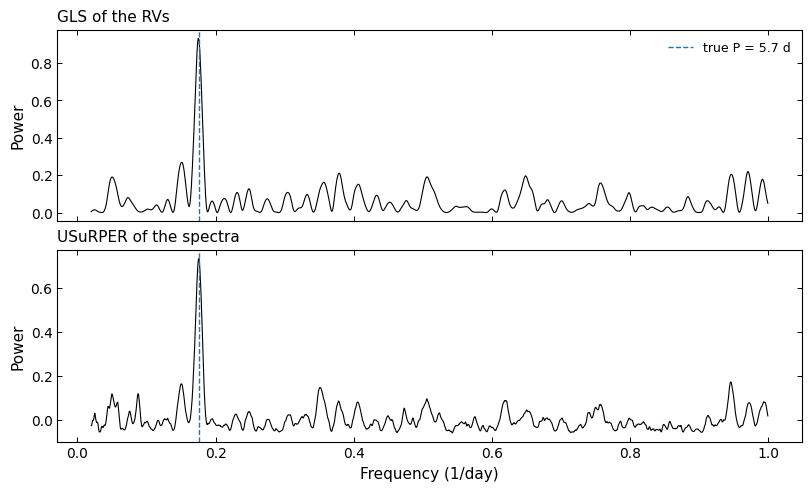

In [13]:
# GLS of the RVs and USuRPER of the spectra (no template)
gls_B = LombScargle(t, vels_B).power(freqs)
usurper_B = pdc_power(t, freqs, unbiased_u_centering(spectral_distance_matrix(waves_B, fluxes_B), n))
# Report the highest peaks
for name, power in (("GLS", gls_B), ("USuRPER", usurper_B)):
    print(f"{name:8s}: highest peak at P = {peak(freqs, power)[0]:.3f} d (power {peak(freqs, power)[1]:.2f})")
print(f"local p-value of the USuRPER peak: {pdc_pvalue(usurper_B.max(), n):.0e}")
# Both periodograms, true period marked
show_periodograms(freqs, {"GLS of the RVs": gls_B, "USuRPER of the spectra": usurper_B},
                  [(P_B, f"true P = {P_B} d", "--")])
plt.show()

Both find 5.7 days. What tells them apart is *how much* the spectrum changes. If the variation
were the Doppler shift the RVs report, the spectrum would change by only as much as a
shift of that amplitude does. Compare that with the actual change, on noise-free spectra:

In [14]:
# Noise-free spectral change, hottest minus coolest, against that of a pure Doppler shift
mid = 0.5 * (f_cool + f_hot)
change = 2 * A_B * (f_hot - f_cool)                     # hottest minus coolest, no noise
shifted = dsp.resample(dsp.doppler_shift_wave(pixels, 2 * semi), mid, pixels, kind="cubic")
# How many times larger the real change is; it must be far larger than a shift's
ratio = np.std(change) / np.std(shifted - mid)
print(f"rms spectral change, coolest to hottest:              {np.std(change):.4f}")
print(f"rms change from a {2 * semi * 1e3:.0f} m/s shift (the RV peak to peak): {np.std(shifted - mid):.4f}")
print(f"ratio: {ratio:.0f}")
assert ratio > 10

rms spectral change, coolest to hottest:              0.0702
rms change from a 23 m/s shift (the RV peak to peak): 0.0011
ratio: 63


The spectrum changes some 60 times more than the RVs account for: this variability is a change
of shape. USuRPER measures the whole change, with no template; the RVs see only the small part
that leaks into the CCF peak position. The partial periodograms (notebook 08) make the split
formal.

## 4. Example C: an unresolved twin binary

Two identical stars (PHOENIX 5500 K, $v\sin i$ = 8 km/s, equal light) on a circular orbit with
$P$ = 6.2 days and $K$ = 4 km/s each, in antiphase. Their largest separation, $2K$ = 8 km/s, is
smaller than a line's width, so the lines never split: they blend into one line that is narrow
and deep at conjunction and broad and shallow at quadrature. The simulator takes the two
components directly.

In [15]:
# Example C: two equal stars in antiphase, blended lines (injected orbit, d and km/s)
P_C, K_C = 6.2, 4.0                                     # days, km/s
v1 = K_C * np.sin(2 * np.pi * t / P_C)
# Simulate the blend: two identical components, equal light, opposite RVs
twin = dict(teff=5500, logg=4.5, vsini=8.0, amplitude=0.5)
sim_C = Simulation(like="HARPS", windows_A=[WINDOW], components=[twin, twin],
                   times=t, rv_kms=np.column_stack([v1, -v1]), snr=100, noise="constant", seed=13)
records_C, _ = simulate(sim_C)
# Plain arrays per epoch
waves_C = [rec.wave[0] for rec in records_C]
fluxes_C = [rec.flux[0] for rec in records_C]
print(f"line width: instrumental FWHM c/R = {dsp.C_KMS / R_HARPS:.1f} km/s, "
      f"rotation ±{twin['vsini']:.0f} km/s; largest separation 2K = {2 * K_C:.0f} km/s")

line width: instrumental FWHM c/R = 2.5 km/s, rotation ±8 km/s; largest separation 2K = 8 km/s


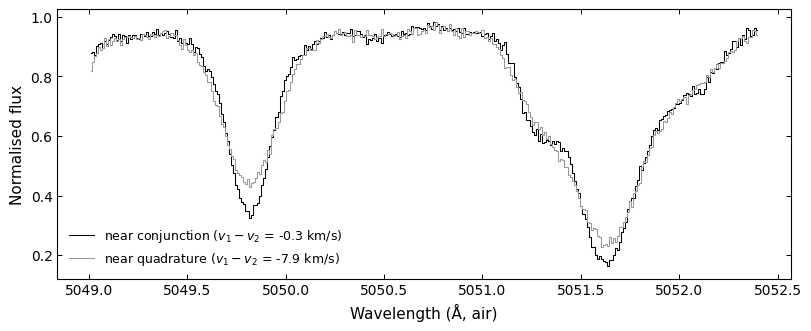

In [16]:
# Blend profile at conjunction (narrow, deep) and at quadrature (broad, shallow)
i_conj, i_quad = np.argmin(np.abs(v1)), np.argmax(np.abs(v1))
zoom = (waves_C[0] > 5049.0) & (waves_C[0] < 5052.4)
fig, ax = plt.subplots(figsize=(8, 3.2))
plot_data(ax, waves_C[0][zoom], fluxes_C[i_conj][zoom],
          label=rf"near conjunction ($v_1 - v_2$ = {2 * v1[i_conj]:+.1f} km/s)")
plot_data(ax, waves_C[0][zoom], fluxes_C[i_quad][zoom], color=GREY,
          label=rf"near quadrature ($v_1 - v_2$ = {2 * v1[i_quad]:+.1f} km/s)")
ax.set_xlabel("Wavelength (Å, air)")
ax.set_ylabel("Normalised flux")
ax.legend(loc="lower left")
plt.show()

**The RVs.** A single-template CCF (the one star's spectrum as template) measures the blend's
centre, and for a symmetric twin system that centre never moves: the two stars' shifts cancel.
The CCF *shape* does change. Its peak drops when the blend is broadest:

In [17]:
# UNICOR RVs with one star's model as template, and how the CCF peak height varies
vels_C, evels_C, peaks_C = measure_rvs(waves_C, fluxes_C, *component_spectra(sim_C)[0][0])
print(f"RV rms: {np.std(vels_C) * 1e3:.1f} m/s (median uncertainty {np.median(evels_C) * 1e3:.1f} m/s); "
      f"the stars move by ±{K_C * 1e3:.0f} m/s")
print(f"CCF peak at conjunction {peaks_C[i_conj]:.4f}, at quadrature {peaks_C[i_quad]:.4f}")

RV rms: 9.0 m/s (median uncertainty 8.0 m/s); the stars move by ±4000 m/s
CCF peak at conjunction 0.9984, at quadrature 0.9825


The line profile depends on the separation $|v_1 - v_2| = 2K\,|\sin(2\pi t/P)|$, which repeats
**twice** per orbit: the blend looks the same at both quadratures and at both conjunctions. So
the spectra, and USuRPER, vary with period $P/2$ = 3.1 days. (Only an asymmetry, such as unequal
stars, brings back a signal at $P$ itself.)

GLS     : highest peak at P = 26.667 d (power 0.21); power at P = 0.00, at P/2 = 0.04
USuRPER : highest peak at P = 3.101 d (power 0.72); power at P = 0.11, at P/2 = 0.72
GLS: false-alarm probability of its highest peak over the whole grid: 0.97
USuRPER: local p-value of its highest peak: 2e-07
USuRPER: highest peak above 0.5/day at P = 1.542 d (power 0.41); P/4 = 1.550 d


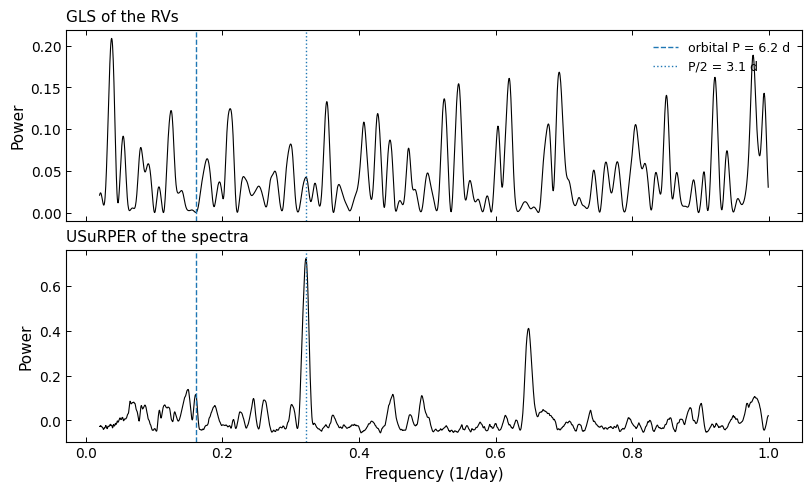

In [18]:
# GLS of the RVs and USuRPER of the spectra
gls_C = LombScargle(t, vels_C).power(freqs)
usurper_C = pdc_power(t, freqs, unbiased_u_centering(spectral_distance_matrix(waves_C, fluxes_C), n))
# Peaks, and power at P and P/2
for name, power in (("GLS", gls_C), ("USuRPER", usurper_C)):
    print(f"{name:8s}: highest peak at P = {peak(freqs, power)[0]:.3f} d (power {peak(freqs, power)[1]:.2f}); "
          f"power at P = {power_at(freqs, power, P_C):.2f}, at P/2 = {power_at(freqs, power, P_C / 2):.2f}")
# GLS false-alarm probability over the whole grid, USuRPER local p-value
fap = LombScargle(t, vels_C).false_alarm_probability(gls_C.max(), minimum_frequency=0.02,
                                                     maximum_frequency=1.0)
print(f"GLS: false-alarm probability of its highest peak over the whole grid: {fap:.2f}")
print(f"USuRPER: local p-value of its highest peak: {pdc_pvalue(usurper_C.max(), n):.0e}")
# Highest USuRPER peak above the P/2 peak, to find its harmonic
high = freqs > 0.5                                      # above the P/2 peak
print(f"USuRPER: highest peak above 0.5/day at P = {peak(freqs[high], usurper_C[high])[0]:.3f} d "
      f"(power {usurper_C[high].max():.2f}); P/4 = {P_C / 4:.3f} d")
# Both periodograms, with P and P/2 marked
show_periodograms(freqs, {"GLS of the RVs": gls_C, "USuRPER of the spectra": usurper_C},
                  [(P_C, f"orbital P = {P_C} d", "--"), (P_C / 2, f"P/2 = {P_C / 2} d", ":")])
plt.show()

The RVs have no periodic signal (their highest GLS peak is consistent with noise), while USuRPER
finds 3.1 days, half the orbital period. Its second peak, at $P/4$, is a harmonic: the profile
does not change sinusoidally. $P/2$ in the spectra with flat RVs is the signature of a blend
whose width changes twice per orbit; the orbital period is then $2 \times 3.1$ = 6.2 days.

## The same numbers with the objects

`Observations` ingests the same spectra (simulated, or a `TimeSeries` of `Spectrum` objects for
Example B); `calc_usurper` chains `spectral_distance_matrix`, `unbiased_u_centering` and
`pdc_power`: identical, bit for bit. `calc_rv_against_template` reaches the same CCF by another
code path (`combine_ccfs`, notebook 03), so the RVs agree to $10^{-9}$ km/s.
[howto/04_find_periods](../howto/04_find_periods.ipynb) is the short recipe.

In [19]:
# Objects: the same analysis through Observations, Template and PeriodicityDetector
from sparta import Observations, Spectrum, Template, TimeSeries
from sparta.instruments.simulated import component_templates

# Same frequency grid as above
GRID = dict(freq_range=(0.02, 1.0), periodogram_grid_resolution=2000)
# Wrap Example B's arrays as Spectrum objects
spectra_B = [Spectrum(wv=[pixels.copy()], sp=[f]) for f in fluxes_B]
# One Observations per example, with its template and the plain-array results to compare
cases = {
    "A": (Observations(survey="SIMULATED", simulation=sim_A), component_templates(sim_A)[0],
          vels_A, usurper_A),
    "B": (Observations(time_series=TimeSeries(times=list(t), vals=spectra_B)),
          Template.from_arrays(fine, mean_flux), vels_B, usurper_B),
    "C": (Observations(survey="SIMULATED", simulation=sim_C), component_templates(sim_C)[0],
          vels_C, usurper_C),
}
# The objects must reproduce the plain-array numbers (USuRPER bit for bit)
for name, (obs, template, vels, usurper) in cases.items():
    obs.calc_rv_against_template(template, dv=0.1, vel_bound=30)
    obs.init_periodicity_detector(**GRID)
    obs.periodicity_detector.calc_usurper()
    assert np.array_equal(obs.periodicity_detector.results_power["USURPER_unbiased"], usurper)
    assert np.allclose(obs.vels, vels, rtol=0, atol=1e-9)          # km/s
    print(f"Example {name}: USuRPER identical; RVs differ by at most {np.max(np.abs(obs.vels - vels)):.1e} km/s")

# RV leak amplitude of Example B from the objects
semi_obj = np.polyfit(np.sin(2 * np.pi * t / P_B), cases["B"][0].vels, 1)[0]
print(f"Example B, the RV leak from the objects: {semi_obj * 1e3:+.1f} m/s")

Example A: USuRPER identical; RVs differ by at most 5.8e-14 km/s
Example B: USuRPER identical; RVs differ by at most 0.0e+00 km/s


Example C: USuRPER identical; RVs differ by at most 0.0e+00 km/s
Example B, the RV leak from the objects: +11.4 m/s


## Summary

- **The idea.** Each spectrum is a point on a unit sphere (`resample_spec_to_common_grid`);
  USuRPER correlates the chords between them (`spectral_distance_matrix`) with the phase
  distances (`unbiased_u_centering`, `pdc_power`). No template, no RVs, blind to flux scale and
  offset.
- **When to reach for it.** When the spectrum may change shape: temperature (Example B: ~60 times
  more change than the spurious 11 m/s RVs imply), unresolved blends (Example C: flat RVs, a
  peak at $P/2$), or no good template. For a star that only moves (Example A), it agrees with
  the RVs.
- **Limits.** One order of overlapping spectra; it says *that* the spectra vary, not *how*; its
  p-values are local ([limitations § Periodograms](../../docs/limitations.md#periodograms)).

**Next:** [`08_partial_pdc`](08_partial_pdc.ipynb): the partial periodograms, which split a
USuRPER signal into Doppler shifts and shape changes.